# CYPLAN 101 - Midterm

## Part 1 Maps

### Import & Set-up

In [1]:
from zipfile import ZipFile
import json
import urllib.request
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np

### Load in Datasets

In [8]:
# Path is slightly adjusted for Midterm Submission
# Keep the GEOID Structure
income_pop = pd.read_csv("Data/ACS_income_pop.csv", dtype={
        "state": str,
        "county": str,
        "tract": str})

tracts = gpd.read_file("Data/tl_2024_06_tract.zip")
places = gpd.read_file("Data/tl_2024_06_place.zip")

# GTFS Data 2026
with ZipFile("Data/gtfs_bus_2026.zip") as feed:
    bus_stops_2026 = pd.read_csv(feed.open("stops.txt"))

with ZipFile("Data/gtfs_rail_2026.zip") as feed:
    rail_stops_2026 = pd.read_csv(feed.open("stops.txt"))

# GTFS Data 2020
with ZipFile("Data/gtfs_bus_2020.zip") as feed:
    bus_stops_2020 = pd.read_csv(feed.open("stops.txt"))

with ZipFile("Data/gtfs_rail_2020.zip") as feed:
    rail_stops_2020 = pd.read_csv(feed.open("stops.txt"))
# Note: We used the Census API to extract the ACS 5-year estimate, but to avoid requesting the API in this notebook, we saved the
# results in a CSV file.

### ACS Data Processing

In [11]:
# Make GEOID on ACS data to join with tracts
income_pop["GEOID"] = income_pop["state"] + income_pop["county"] + income_pop["tract"]

# make sure attributes are correct data type before joining
tracts["GEOID"] = tracts["GEOID"].astype(str)
income_pop["GEOID"] = income_pop["GEOID"].astype(str)
income_pop["B01003_001E"] = income_pop["B01003_001E"].astype(int)
income_pop["B19013_001E"] = income_pop["B19013_001E"].astype(float)
tracts_income = tracts.merge(income_pop, on="GEOID", how="inner").copy()

# Only keep essential columns for our analysis
tracts_income = tracts_income.loc[:,["GEOID", "NAME_x", "B01003_001E", "B19013_001E", "INTPTLAT", "INTPTLON", "geometry"]]

# rename columns
names = {
    "NAME_x": "Tract_Name",
    "B01003_001E": "Total_Population",
    "B19013_001E": "Median_Household_Income"
}

tracts_income = tracts_income.rename(columns=names)
tracts_income.head()

,GEOID,Tract_Name,Total_Population,Median_Household_Income,INTPTLAT,INTPTLON,geometry
0,06037204920,2049.20,2274,75972.0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
1,06037205110,2051.10,3501,54939.0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
2,06037205120,2051.20,3252,32406.0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."
3,06037206010,2060.10,3392,70304.0,+34.0682177,-118.2320356,"POLYGON ((-118.23924 34.06726, -118.238 34.067..."
4,06037206020,2060.20,7629,155658.0,+34.0571230,-118.2311021,"POLYGON ((-118.23787 34.05427, -118.23784 34.0..."


#### Fix Income with No Estimate to NaN

In [12]:
tracts_income["Median_Household_Income"] = tracts_income["Median_Household_Income"].replace(
    -666666666, np.nan)

## GTFS Data Processing
### Inspect to see if they have missing records on the IDs that will be used to join datasets

In [16]:
paths = {
    "bus2020": "Data/gtfs_bus_2020.zip",
    "bus2026": "Data/gtfs_bus_2026.zip",
    "rail2020": "Data/gtfs_rail_2020.zip",
    "rail2026": "Data/gtfs_rail_2026.zip"
}

In [17]:
files_names = ["stops.txt", "routes.txt", "trips.txt", "stop_times.txt", "calendar.txt", "calendar_dates.txt", "shapes.txt"]
for name, path in paths.items():
    print("="*20)
    print(f"GTFS of: {name}")

    with ZipFile(path) as feed:
        print("="*20)
        for file in files_names:
            data = pd.read_csv(feed.open(file))

            print("="*20)
            print(f"For {file}:")
            print("Rows:", len(data))
            print("Columns:", data.columns.tolist())
            
            print("Missing Counts:")
            print(data.isna().sum().to_dict())

# Expand the output for complete results

GTFS of: bus2020
For stops.txt:
Rows: 13807
Columns: ['stop_id', 'stop_code', 'stop_name', 'stop_desc', 'stop_lat', 'stop_lon', 'stop_url', 'location_type', 'parent_station', 'tpis_name']
Missing Counts:
{'stop_id': 0, 'stop_code': 0, 'stop_name': 0, 'stop_desc': 13807, 'stop_lat': 0, 'stop_lon': 0, 'stop_url': 13807, 'location_type': 13807, 'parent_station': 13807, 'tpis_name': 13807}
For routes.txt:
Rows: 133
Columns: ['route_id', 'route_short_name', 'route_long_name', 'route_desc', 'route_type', 'route_color', 'route_text_color', 'route_url']
Missing Counts:
{'route_id': 0, 'route_short_name': 2, 'route_long_name': 0, 'route_desc': 0, 'route_type': 0, 'route_color': 112, 'route_text_color': 112, 'route_url': 131}
For trips.txt:
Rows: 27260
Columns: ['route_id', 'service_id', 'trip_id', 'trip_headsign', 'direction_id', 'block_id', 'shape_id']
Missing Counts:
{'route_id': 0, 'service_id': 0, 'trip_id': 0, 'trip_headsign': 27260, 'direction_id': 0, 'block_id': 0, 'shape_id': 0}
For sto

/tmp/ipykernel_95/509002609.py:9: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(feed.open(file))


For stop_times.txt:
Rows: 2106179
Columns: ['trip_id', 'arrival_time', 'departure_time', 'stop_id', 'stop_sequence', 'stop_headsign', 'pickup_type', 'drop_off_type', 'trip_id_event', 'route_code', 'destination_code', 'timepoint', 'bay_num']
Missing Counts:
{'trip_id': 0, 'arrival_time': 0, 'departure_time': 0, 'stop_id': 0, 'stop_sequence': 0, 'stop_headsign': 0, 'pickup_type': 0, 'drop_off_type': 0, 'trip_id_event': 0, 'route_code': 0, 'destination_code': 0, 'timepoint': 0, 'bay_num': 2085517}
For calendar.txt:
Rows: 129
Columns: ['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']
Missing Counts:
{'service_id': 0, 'monday': 0, 'tuesday': 0, 'wednesday': 0, 'thursday': 0, 'friday': 0, 'saturday': 0, 'sunday': 0, 'start_date': 0, 'end_date': 0}
For calendar_dates.txt:
Rows: 7086
Columns: ['service_id', 'date', 'exception_type']
Missing Counts:
{'service_id': 0, 'date': 0, 'exception_type': 0}
For shapes.txt:
Rows: 344948

### Merge Bus & Rail stops

In [18]:
# Make a new column to differentiate Bus & Rail Stops
bus_stops_2026["mode"] = "bus"
rail_stops_2026['mode'] = "rail"

bus_stops_2020["mode"] = "bus"
rail_stops_2020['mode'] = "rail"

# Merge
stops_2026 = pd.concat([bus_stops_2026, rail_stops_2026], ignore_index=True)
stops_2020 = pd.concat([bus_stops_2020, rail_stops_2020], ignore_index=True)

# Select the essential columns
all_stops_2026 = stops_2026.copy().loc[:, ["stop_id", "stop_name", "stop_lat", "stop_lon", "mode"]]
all_stops_2020 = stops_2020.copy().loc[:, ["stop_id", "stop_name", "stop_lat", "stop_lon", "mode"]]

print(f"2026 GTFS Stop Summary:")
print(f"# of Bus stops: {len(bus_stops_2026)}, Rail stops: {len(rail_stops_2026)}, Combined: {len(all_stops_2026)}.")
display(all_stops_2026.head())

print(f"2020 GTFS Stop Summary:")
print(f"# of Bus stops: {len(bus_stops_2020)}, Rail stops: {len(rail_stops_2020)}, Combined: {len(all_stops_2020)}.")
display(all_stops_2020.head())

2026 GTFS Stop Summary:
# of Bus stops: 11892, Rail stops: 463, Combined: 12355.


,stop_id,stop_name,stop_lat,stop_lon,mode
0,1,Paramount / Slauson,33.973248,-118.113113,bus
1,3,Jefferson / 10th,34.025471,-118.328402,bus
2,6,120th / Augustus F Hawkins,33.924696,-118.242222,bus
3,7,120th / Martin Luther King Hospital,33.924505,-118.240369,bus
4,12,15054 Sherman Way,34.201075,-118.461953,bus


2020 GTFS Stop Summary:
# of Bus stops: 13807, Rail stops: 394, Combined: 14201.


,stop_id,stop_name,stop_lat,stop_lon,mode
0,1,Paramount / Slauson,33.973248,-118.113113,bus
1,3,Jefferson / 10th,34.025471,-118.328402,bus
2,6,120th / Augustus F Hawkins,33.924696,-118.242222,bus
3,7,120th / Martin Luther King Hospital,33.924505,-118.240369,bus
4,8,120th / Crenshaw,33.923818,-118.326886,bus


### Convert GTFS to GeoDataFrame

In [40]:
# CRS needs to be EPSG:4629 to ensure consistency with Tracts Data
stops_2026_gdf = gpd.GeoDataFrame(all_stops_2026, 
                             geometry = gpd.points_from_xy(all_stops_2026["stop_lon"],all_stops_2026["stop_lat"]),
                             crs = "EPSG:4269")

stops_2020_gdf = gpd.GeoDataFrame(all_stops_2020, 
                             geometry = gpd.points_from_xy(all_stops_2020["stop_lon"],all_stops_2020["stop_lat"]),
                             crs = "EPSG:4269")
stops_2026_gdf.to_csv("Data/processed/GTFS_stops_2026.csv")
stops_2020_gdf.to_csv("Data/processed/GTFS_stops_2020.csv")

## TIGER Boundary Processing
### Filter the "places" to only City of LA

In [21]:
la = places.copy()

la_mask = la['NAME'].str.strip() == "Los Angeles"
la = la[la_mask]
la

,STATEFP,PLACEFP,PLACENS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,PCICBSA,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
138,06,44000,02410877,0644000,1600000US0644000,Los Angeles,Los Angeles city,25,C1,Y,G4110,A,1218641632,80409616,+34.0193936,-118.4108248,"POLYGON ((-118.66818 34.18987, -118.66815 34.1..."


### Spatially interesects with ACS to find tracts that are in the city

In [22]:
# Extract the City of LA Boundary
city_bound = la.geometry.union_all()

# Also filter out the ones that could be partially in the boundary
intersecting = tracts_income[tracts_income.intersects(city_bound)]
within = tracts_income[tracts_income.within(city_bound)]
partial = intersecting.loc[~intersecting.index.isin(within.index)].copy()

print("Tracts intersecting the city:", len(intersecting))
print("Tracts fully within the city:", len(within))
print("Intersecting but not fully within:", len(partial))

Tracts intersecting the city: 1305
Tracts fully within the city: 1096
Intersecting but not fully within: 209


## Analysis to determine whether to include partial tracts or not
### Using total population from ACS estimates

In [23]:
pop_col = "Total_Population"

within_pop = within[pop_col].sum()
partial_pop = partial[pop_col].sum()
intersecting_pop = intersecting[pop_col].sum()

# Summary Table including Tract Count and Previously Computed Population Total and Share.
summary = pd.DataFrame({
    "Group": ["Fully Within", "Partial", "All Intersecting"],
    "Tract_Count": [
        len(within),
        len(partial),
        len(intersecting)
    ],
    "Population": [
        within_pop,
        partial_pop,
        intersecting_pop
    ]
})

summary["Population_Share"] = (
    summary["Population"] / intersecting_pop * 100
)

display(summary)

,Group,Tract_Count,Population,Population_Share
0,Fully Within,1096,3804790,81.940184
1,Partial,209,838585,18.059816
2,All Intersecting,1305,4643375,100.000000


Looking at populations, it seems like we will be missing about 800k people who lived in the partial tracts, which is about 18.06% of the population out of all intersecting tracts. From this perspective, we should consider including them in our analysis. Let's further inspect these metrics.

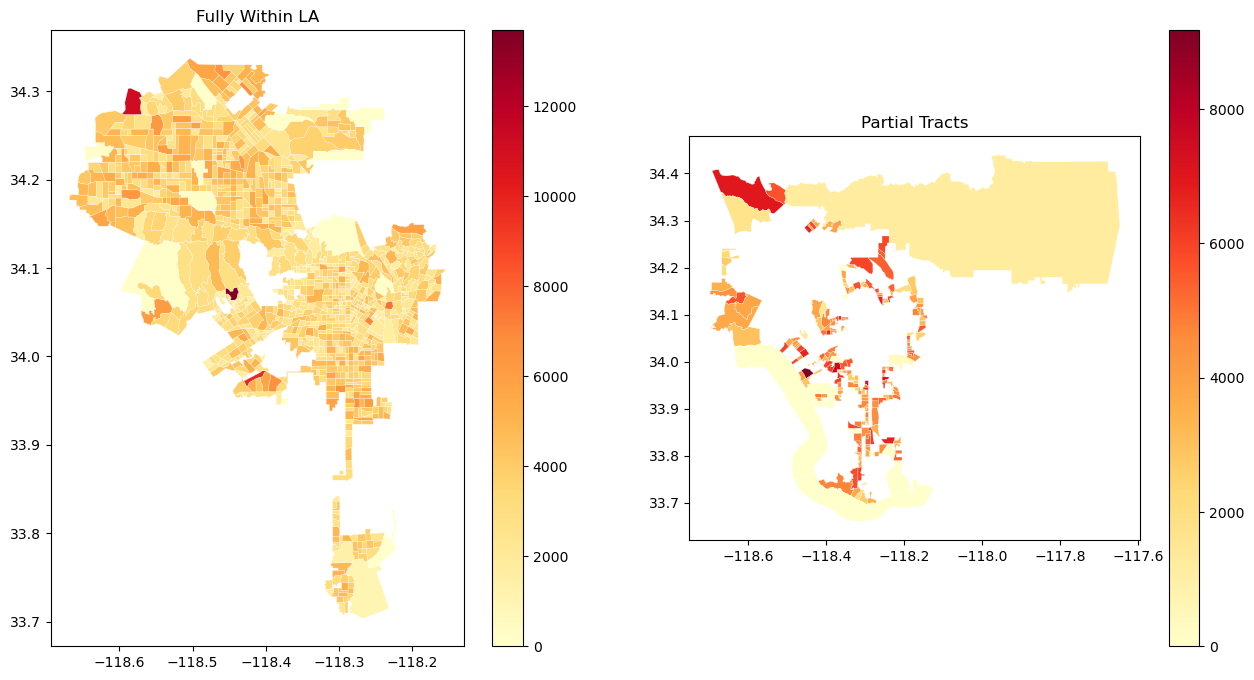

In [24]:
# Visually inspect where the population is spread in the Tracts
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Fully contained tracts
within.plot(
    column=pop_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[0],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[0].set_title("Fully Within LA")

# Partial tracts
partial.plot(
    column=pop_col,
    cmap="YlOrRd",
    legend=True,
    ax=axes[1],
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgray"}
)

axes[1].set_title("Partial Tracts")
plt.show()

Using tables and maps, we numerically and visually inspect how excluding the partial tracts might have an effect in terms of population we are missing in the analysis. However, we should also consider using Median Household Income since this socioeconomic factor will be used as part of our analysis; therefore, if there are tracts that don't have available income data, we should consider removing those first. In addition, we should also consider bringing in our main datasets - GTFS Schedule Data since if there are Tracts that don't have any bus/rail stops, this is also a factor to consider when excluding them from our analysis.

### Using Median Household Income from ACS Estimates

In [26]:
income_col = "Median_Household_Income"

within_income = within[income_col]
partial_income = partial[income_col]
intersecting_income = intersecting[income_col]

income_summary = pd.DataFrame({
    "Group": ["Fully Within", "Partial", "All Intersecting"],
    "Tract_Count": [len(within), len(partial), len(intersecting)],
    "Valid_Tract_Count": [
        within[income_col].count(),
        partial[income_col].count(),
        intersecting[income_col].count(),
    ],
    "Mean_Income": [
        within_income.mean(),
        partial_income.mean(),
        intersecting_income.mean()
    ],
    "Median_Income": [
        within_income.median(),
        partial_income.median(),
        intersecting_income.median()
    ]
})

display(income_summary)

,Group,Tract_Count,Valid_Tract_Count,Mean_Income,Median_Income
0,Fully Within,1096,1080,87983.610185,79406.5
1,Partial,209,195,109749.364103,99806.0
2,All Intersecting,1305,1275,91312.490196,83270.0


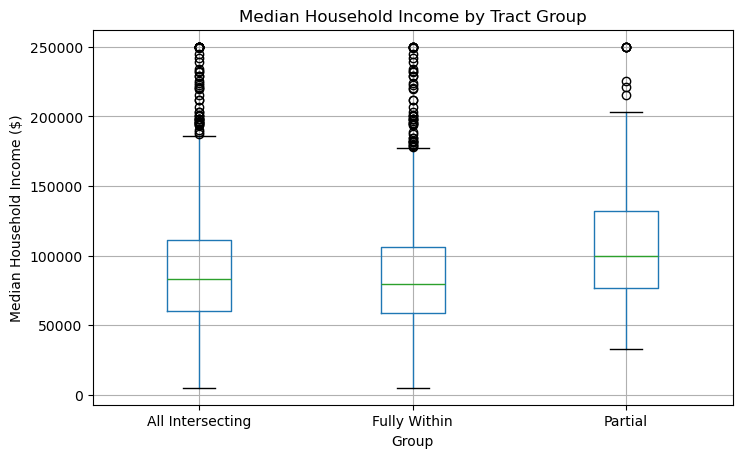

In [27]:
income_comparison = pd.DataFrame({
    "Income": pd.concat([
        within[income_col],
        partial[income_col],
        intersecting[income_col]
    ]),
    "Group": (
        ["Fully Within"] * len(within)
        + ["Partial"] * len(partial)
        + ["All Intersecting"] * len(intersecting)
    )
})

income_comparison.boxplot(
    column="Income",
    by="Group",
    figsize=(8, 5)
)

plt.title("Median Household Income by Tract Group")
plt.suptitle("")
plt.ylabel("Median Household Income ($)")
plt.show()

After numerically and visually inspecting the difference between each tract group in terms of median household income, we could conclude that partially overlapped tracts overall have a higher median household income compared with the other two groups, but it is inconclusive to exclude them from part of the analysis.

### Using GTFS Schedule Data

In [29]:
la_stops_2026_gdf = stops_2026_gdf[stops_2026_gdf.within(city_bound)].copy()
la_stops_2020_gdf = stops_2020_gdf[stops_2020_gdf.within(city_bound)].copy()

In [30]:
# Spatial Join Bus/Rail Stops in LA City with Partial Census Tracts
partial_stop_2026_join = gpd.sjoin(
    la_stops_2026_gdf,
    partial[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

partial_stop_2020_join = gpd.sjoin(
    la_stops_2020_gdf,
    partial[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

In [31]:
# Quick Summary
print(f"2026 Summary:")
print("Stops by mode:")
print(partial_stop_2026_join["mode"].value_counts())

print("\nUnique partial tracts with stops:")
print(partial_stop_2026_join["GEOID"].nunique())

print("\nPartial tracts without stops:")
print(len(partial) - partial_stop_2026_join["GEOID"].nunique())

print("="*30)
print(f"2020 Summary:")
print("Stops by mode:")
print(partial_stop_2020_join["mode"].value_counts())

print("\nUnique partial tracts with stops:")
print(partial_stop_2020_join["GEOID"].nunique())

print("\nPartial tracts without stops:")
print(len(partial) - partial_stop_2020_join["GEOID"].nunique())

2026 Summary:
Stops by mode:
mode
bus     93
rail     5
Name: count, dtype: int64

Unique partial tracts with stops:
11

Partial tracts without stops:
198
2020 Summary:
Stops by mode:
mode
bus     104
rail      5
Name: count, dtype: int64

Unique partial tracts with stops:
11

Partial tracts without stops:
198


With this initial summary, we could notice that both 2020 and 2026 have 11 unique partially overlapped tracts with bus/rail stops, and 198 tracts without bus/rail stops. These 11 tracts are likely the same for both periods.

In [32]:
# Inspect the 11 tracts with stops
partial_with_stops_2026 = partial.merge(
    partial_stop_2026_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="inner"
)

display(partial_with_stops_2026[ ["GEOID", pop_col, income_col] ])

partial_with_stops_2020 = partial.merge(
    partial_stop_2020_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="inner"
)

display(partial_with_stops_2020[ ["GEOID", pop_col, income_col] ])
same_tract = partial_with_stops_2020["GEOID"] == partial_with_stops_2026["GEOID"]
print(f"Is the 11 Tracts the same for both periods?")
print(same_tract)

,GEOID,Total_Population,Median_Household_Income
0,06037275605,2915,119783.0
1,06037980028,0,NaN
2,06037297501,2697,168942.0
3,06037135205,2067,156389.0
4,06037292001,4522,54319.0
5,06037104124,3950,83958.0
6,06037278102,2917,174167.0
7,06037297601,3579,90556.0
8,06037104204,3577,76250.0
9,06037274202,4286,116552.0


,GEOID,Total_Population,Median_Household_Income
0,06037275605,2915,119783.0
1,06037980028,0,NaN
2,06037297501,2697,168942.0
3,06037135205,2067,156389.0
4,06037292001,4522,54319.0
5,06037104124,3950,83958.0
6,06037278102,2917,174167.0
7,06037297601,3579,90556.0
8,06037104204,3577,76250.0
9,06037274202,4286,116552.0


Is the 11 Tracts the same for both periods?
0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
Name: GEOID, dtype: bool


In [33]:
# Identify partial tracts without transit stops; since the tracts would be the same, we would do this once
partial_without_stops = partial.merge(
    partial_stop_2026_join[["GEOID"]].drop_duplicates(),
    on="GEOID",
    how="left",
    indicator=True
)

partial_without_stops = partial_without_stops[
    partial_without_stops["_merge"] == "left_only"
].copy()

# Compare the two groups
comparison = pd.DataFrame({
    "Group": ["With Stops", "Without Stops"],
    "Tract_Count": [
        len(partial_with_stops_2026),
        len(partial_without_stops)
    ],
    "Total_Population": [
        partial_with_stops_2026[pop_col].sum(),
        partial_without_stops[pop_col].sum()
    ],
    "Median_Population": [
        partial_with_stops_2026[pop_col].median(),
        partial_without_stops[pop_col].median()
    ],
    "Median_HH_Income": [
        partial_with_stops_2026[income_col].median(),
        partial_without_stops[income_col].median()
    ]
})

display(comparison)

,Group,Tract_Count,Total_Population,Median_Population,Median_HH_Income
0,With Stops,11,34319,3577.0,117718.5
1,Without Stops,198,804266,4165.5,99750.0


After inspecting the partially overlapping tracts with stops, we decided we would provisonally keep these tracts because accessibility could also be determine through walking accessbility. Therefore, those tracts that might not have service could still have the option to walk to the nearest stop.

## GeoDataFrame that contain all intersecting tract stops

In [34]:
intersecting_stops_2026_gdf = gpd.sjoin(
    stops_2026_gdf,
    intersecting[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

intersecting_stops_2020_gdf = gpd.sjoin(
    stops_2020_gdf,
    intersecting[["GEOID", "geometry"]],
    how="inner",
    predicate="within"
)

intersecting_stops_2026_gdf = intersecting_stops_2026_gdf.drop(columns = ["index_right", "GEOID"]).copy()
intersecting_stops_2020_gdf = intersecting_stops_2020_gdf.drop(columns = ["index_right", "GEOID"]).copy()

## Final Results

In [35]:
# This contains all intersecting Tracts of ACS Data
intersecting_acs = intersecting.copy()
display(intersecting.head(3))

# This contains all intersecting Tracts of GTFS data for 2026 and 2020

display(la_stops_2026_gdf.head(3))
display(la_stops_2020_gdf.head(3))

# This is the City of LA Boundary
display(la)

,GEOID,Tract_Name,Total_Population,Median_Household_Income,INTPTLAT,INTPTLON,geometry
0,06037204920,2049.20,2274,75972.0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
1,06037205110,2051.10,3501,54939.0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
2,06037205120,2051.20,3252,32406.0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."


,stop_id,stop_name,stop_lat,stop_lon,mode,geometry
1,3,Jefferson / 10th,34.025471,-118.328402,bus,POINT (-118.3284 34.02547)
4,12,15054 Sherman Way,34.201075,-118.461953,bus,POINT (-118.46195 34.20108)
5,16,Riverside / Los Feliz,34.116932,-118.271486,bus,POINT (-118.27149 34.11693)


,stop_id,stop_name,stop_lat,stop_lon,mode,geometry
1,3,Jefferson / 10th,34.025471,-118.328402,bus,POINT (-118.3284 34.02547)
7,12,15054 Sherman Way,34.201075,-118.461953,bus,POINT (-118.46195 34.20108)
10,16,Riverside / Los Feliz,34.116932,-118.271486,bus,POINT (-118.27149 34.11693)


,STATEFP,PLACEFP,PLACENS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,PCICBSA,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
138,06,44000,02410877,0644000,1600000US0644000,Los Angeles,Los Angeles city,25,C1,Y,G4110,A,1218641632,80409616,+34.0193936,-118.4108248,"POLYGON ((-118.66818 34.18987, -118.66815 34.1..."


In [36]:
intersecting_tracts = tracts[tracts.intersects(city_bound)]
display(intersecting_tracts.head(3))
print(intersecting_tracts.shape)

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
2,06,037,204920,06037204920,1400000US06037204920,2049.20,Census Tract 2049.20,G5020,S,909972,0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
3,06,037,205110,06037205110,1400000US06037205110,2051.10,Census Tract 2051.10,G5020,S,286962,0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
4,06,037,205120,06037205120,1400000US06037205120,2051.20,Census Tract 2051.20,G5020,S,1466242,0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."


(1308, 14)


Although there are 1308 intersecting tracts if we used the TIGER tracts and spatially intersect with the TIGER City Boundary, we would instead use the ACS-matched 1305 tracts because we are mapping the socioeconomic factor, which is only available via the ACS 5-year estimate.

## Save the Results to CSV

In [39]:
# ACS Data
intersecting_acs.to_csv("Data/processed/ACS_income_pop_la_intersecting.csv")

# GTFS Stops inside City of LA for 2026 and 2020
la_stops_2026_gdf.to_csv("Data/processed/GTFS_stops_la_2026.csv")
la_stops_2020_gdf.to_csv("Data/processed/GTFS_stops_la_2020.csv")

# GTFS Stops in All Intersecting LA Tracts Data for 2026 and 2020
intersecting_stops_2026_gdf.to_csv("Data/processed/GTFS_stops_2026.csv")
intersecting_stops_2020_gdf.to_csv("Data/processed/GTFS_stops_2020.csv")

# City of LA Boundary
la.to_csv("Data/processed/la_boundary.csv")

# Part 2: LA Metro Bus Accessibility Charts
## Key Info: 
* Study area: City of LA
* Comparison dates: Monday October 19th,2020 & Monday, October 19th, 2026 for scheduled serice
* Sources: LA Metro bus GTFS, Census TIGER/Line 2024, ACS 2020-2024 5-year estimates

# Data Cleaning
* ACS file contains a descriptive row that's removed
* treat non-numeric & negative income codes as missing
* census tracts are selected by intersecting the City of LA boundary
* bus stops are converted to point geometries & spatially filterd to city limits

In [42]:
import pandas as pd

In [43]:
acs=pd.read_csv("Data/ACSDT5Y2024.B19013-Data.csv")
acs.head()

,GEO_ID,NAME,B19013_001E,B19013_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Median household income in the past ...,Margin of Error!!Median household income in th...,NaN
1,1400000US06037101110,Census Tract 1011.10; Los Angeles County; Cali...,88438,20688,NaN
2,1400000US06037101122,Census Tract 1011.22; Los Angeles County; Cali...,104643,40990,NaN
3,1400000US06037101220,Census Tract 1012.20; Los Angeles County; Cali...,92317,21248,NaN
4,1400000US06037101221,Census Tract 1012.21; Los Angeles County; Cali...,52204,17943,NaN


In [44]:
acs=acs.iloc[1:].copy() #remove 1st row with column info
acs.head()

,GEO_ID,NAME,B19013_001E,B19013_001M,Unnamed: 4
1,1400000US06037101110,Census Tract 1011.10; Los Angeles County; Cali...,88438,20688,NaN
2,1400000US06037101122,Census Tract 1011.22; Los Angeles County; Cali...,104643,40990,NaN
3,1400000US06037101220,Census Tract 1012.20; Los Angeles County; Cali...,92317,21248,NaN
4,1400000US06037101221,Census Tract 1012.21; Los Angeles County; Cali...,52204,17943,NaN
5,1400000US06037101222,Census Tract 1012.22; Los Angeles County; Cali...,38125,37622,NaN


In [45]:
# convert income to numberss and replace missing values
acs["B19013_001E"]=pd.to_numeric(acs["B19013_001E"],errors="coerce")
acs.loc[acs['B19013_001E']<0,"B19013_001E"]=None

In [46]:
# create census tract GEOID to later match ACS w/ boundaries
acs["GEOID"]=acs["GEO_ID"].str[-11:]
acs=acs.rename(columns={"B19013_001E": "median_income"})
acs[["GEOID", "NAME", "median_income"]].head()

,GEOID,NAME,median_income
1,06037101110,Census Tract 1011.10; Los Angeles County; Cali...,88438.0
2,06037101122,Census Tract 1011.22; Los Angeles County; Cali...,104643.0
3,06037101220,Census Tract 1012.20; Los Angeles County; Cali...,92317.0
4,06037101221,Census Tract 1012.21; Los Angeles County; Cali...,52204.0
5,06037101222,Census Tract 1012.22; Los Angeles County; Cali...,38125.0


In [47]:
# LA Metro Bus GTFS dataset 2026
stops_2026=pd.read_csv("Data/GTFS_bus_2026.zip/stops.txt")
stops_2026.head()

,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,stop_url,location_type,parent_station,tpis_name
0,1,1,Paramount / Slauson,NaN,33.973248,-118.113113,NaN,NaN,NaN,NaN
1,3,3,Jefferson / 10th,NaN,34.025471,-118.328402,NaN,NaN,NaN,NaN
2,6,6,120th / Augustus F Hawkins,NaN,33.924696,-118.242222,NaN,NaN,NaN,NaN
3,7,7,120th / Martin Luther King Hospital,NaN,33.924505,-118.240369,NaN,NaN,NaN,NaN
4,12,12,15054 Sherman Way,NaN,34.201075,-118.461953,NaN,NaN,NaN,NaN


In [48]:
# number of bus stops
len(stops_2026)

11892

In [49]:
# check for duplicate stop IDs
stops_2026['stop_id'].nunique()

11892

In [50]:
# LA Metro Bus GTFS dataset 2020
stops_2020=pd.read_csv("Data/GTFS_bus_2020/stops.txt")
stops_2020.head()

,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,stop_url,location_type,parent_station,tpis_name
0,1,1,Paramount / Slauson,NaN,33.973248,-118.113113,NaN,NaN,NaN,NaN
1,3,3,Jefferson / 10th,NaN,34.025471,-118.328402,NaN,NaN,NaN,NaN
2,6,6,120th / Augustus F Hawkins,NaN,33.924696,-118.242222,NaN,NaN,NaN,NaN
3,7,7,120th / Martin Luther King Hospital,NaN,33.924505,-118.240369,NaN,NaN,NaN,NaN
4,8,8,120th / Crenshaw,NaN,33.923818,-118.326886,NaN,NaN,NaN,NaN


In [51]:
import geopandas as gpd
tracts=gpd.read_file("Data/tl_2024_06_tract.zip")
cities=gpd.read_file("Data/tl_2024_06_place.zip")
tracts.head()

,STATEFP,COUNTYFP,TRACTCE,GEOID,GEOIDFQ,NAME,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,06,001,442700,06001442700,1400000US06001442700,4427,Census Tract 4427,G5020,S,1234016,0,+37.5371513,-122.0081095,"POLYGON ((-122.01721 37.53932, -122.01719 37.5..."
1,06,001,442800,06001442800,1400000US06001442800,4428,Census Tract 4428,G5020,S,1278646,0,+37.5293619,-121.9931002,"POLYGON ((-122.0023 37.52984, -122.00224 37.52..."
2,06,037,204920,06037204920,1400000US06037204920,2049.20,Census Tract 2049.20,G5020,S,909972,0,+34.0175004,-118.1974975,"POLYGON ((-118.20284 34.01966, -118.20283 34.0..."
3,06,037,205110,06037205110,1400000US06037205110,2051.10,Census Tract 2051.10,G5020,S,286962,0,+34.0245059,-118.2142985,"POLYGON ((-118.21964 34.02628, -118.21945 34.0..."
4,06,037,205120,06037205120,1400000US06037205120,2051.20,Census Tract 2051.20,G5020,S,1466242,0,+34.0187542,-118.2117951,"POLYGON ((-118.22023 34.02056, -118.22018 34.0..."


In [52]:
# Filter for LA County census tracts
la_tracts=tracts[tracts['COUNTYFP']=='037']
# City of LA
la_city=cities[cities['PLACEFP']=='44000']
print("LA County census tracts:", len(la_tracts))
print("City of LA boundaries:", len(la_city))

LA County census tracts: 2498
City of LA boundaries: 1


In [53]:
la_city_tracts=gpd.sjoin(la_tracts, la_city[['geometry']], how='inner', predicate='intersects')
print('Census tracts in City of LA:', len(la_city_tracts))
# Ensure one row per tract before aggregating counts
la_city_tracts=la_city_tracts.drop_duplicates(subset="GEOID").copy()
print("Unique intersecting census tracts:", len(la_city_tracts))


Census tracts in City of LA: 1305
Unique intersecting census tracts: 1305


In [54]:
#create geographic points of 2026 bus stops
bus_geo_2026=gpd.GeoDataFrame(stops_2026, geometry=gpd.points_from_xy(
    stops_2026['stop_lon'], stops_2026['stop_lat']),
                              crs="EPSG:4326")
bus_geo_2026=bus_geo_2026.to_crs(la_city.crs)
la_bus_2026=gpd.sjoin(bus_geo_2026, la_city[['geometry']],how='inner', predicate='within')
print('2026 bus stops in City of LA:', len(la_bus_2026))

2026 bus stops in City of LA: 6954


In [55]:
# now for 2020 bus stops
bus_geo_2020=gpd.GeoDataFrame(stops_2020, geometry=gpd.points_from_xy(
    stops_2020['stop_lon'], stops_2020['stop_lat']),crs="EPSG:4326")
bus_geo_2020=bus_geo_2020.to_crs(la_city.crs)
la_bus_2020=gpd.sjoin(bus_geo_2020, la_city[['geometry']], how='inner', predicate='within')
print('2020 bus stops in City of LA:', len(la_bus_2020))

2020 bus stops in City of LA: 7784


## Figure 1: Bus stop records, 2020 vs 2026

<Axes: title={'center': 'LA Metro Bus Stop Records in the City of Los Angeles'}, xlabel='Year', ylabel='Number of Stop Records'>

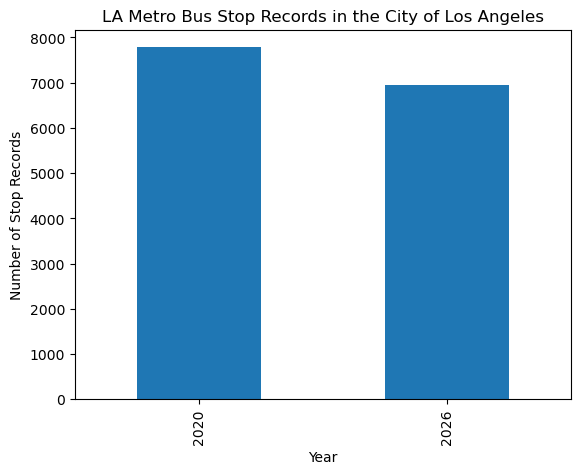

In [56]:
# LA Metro Bus Stop Records in the City of LA
la_stop_counts=pd.Series({'2020': len(la_bus_2020), '2026': len(la_bus_2026)})
la_stop_counts.plot.bar(
    title="LA Metro Bus Stop Records in the City of Los Angeles",
    xlabel="Year",ylabel="Number of Stop Records")

Figure 1. Comparison of LA Metro bus stop records within the City of Los Angeles in 2020 & 2026. The number of bus stops decreased from 7784 in 2020 to 6954 in 2026, representing a 10.7% reduction. This suggests a decline in the number of recorded bus stop locations over the 6-yera period, although it doesn't necessarily indicate a reduction in bus service frequency. 

## Figure 2: Bus stops per census tract

In [57]:
# assign bus stops to census tracts
stops_by_tract_2026=gpd.sjoin(la_bus_2026.drop(columns='index_right'),
                              la_city_tracts[['GEOID', 'geometry']],how='inner', predicate='within')
stops_by_tract_2026.head()

,stop_id,stop_code,stop_name,stop_desc,stop_lat,stop_lon,stop_url,location_type,parent_station,tpis_name,geometry,index_right,GEOID
1,3,3,Jefferson / 10th,NaN,34.025471,-118.328402,NaN,NaN,NaN,NaN,POINT (-118.3284 34.02547),5283,06037219300
4,12,12,15054 Sherman Way,NaN,34.201075,-118.461953,NaN,NaN,NaN,NaN,POINT (-118.46195 34.20108),2463,06037127210
5,16,16,Riverside / Los Feliz,NaN,34.116932,-118.271486,NaN,NaN,NaN,NaN,POINT (-118.27149 34.11693),4134,06037980009
7,19,19,Indiana / Olympic,NaN,34.018999,-118.192361,NaN,NaN,NaN,NaN,POINT (-118.19236 34.019),2,06037204920
10,31,31,3rd / Gardner,NaN,34.070240,-118.353264,NaN,NaN,NaN,NaN,POINT (-118.35326 34.07024),1405,06037214505


In [58]:
# count stops in each tract
tract_counts_2026=(stops_by_tract_2026.groupby("GEOID").size().reset_index(name='stop_count'))
tract_counts_2026.head()

,GEOID,stop_count
0,06037101110,2
1,06037101220,4
2,06037101221,1
3,06037101222,4
4,06037101300,7


In [59]:
# include tracts w/ 0 stops
all_tract_counts_2026=la_city_tracts[['GEOID']].merge(tract_counts_2026, on='GEOID', how='left')
all_tract_counts_2026['stop_count']=(all_tract_counts_2026['stop_count'].fillna(0))


In [60]:
# assign 2020 bus stops to census tracts
stops_by_tract_2020=gpd.sjoin(la_bus_2020.drop(columns="index_right"), la_city_tracts[['GEOID', 'geometry']],
                              how='inner',predicate='within')
# count 2020 stops in each tract
tract_counts_2020=(stops_by_tract_2020.groupby('GEOID').size().reset_index(name='stop_count'))
# include ones w/ 0 stops
all_tract_counts_2020=la_city_tracts[['GEOID']].merge(tract_counts_2020,
                                                      on='GEOID', how='left')
all_tract_counts_2020['stop_count']=(all_tract_counts_2020['stop_count'].fillna(0))


<Axes: title={'center': 'LA Metro Bus Stops per Census Tract: 2020 vs 2026'}, xlabel='Number of Bus Stops', ylabel='Number of Census Tracts'>

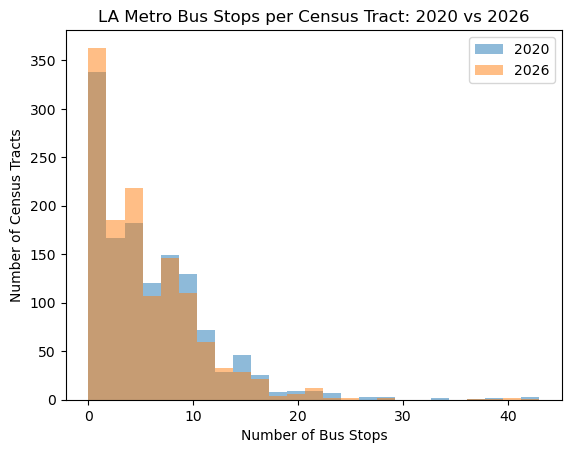

In [61]:
# combine 2020 & 2026
comparison=pd.DataFrame({'2020':all_tract_counts_2020.set_index('GEOID')['stop_count'],
                         '2026': all_tract_counts_2026.set_index('GEOID')['stop_count']})
comparison.plot.hist(bins=25,alpha=0.5,
                     title='LA Metro Bus Stops per Census Tract: 2020 vs 2026',
                     xlabel='Number of Bus Stops', ylabel='Number of Census Tracts')

Figure 2. Distribution of LA Metro bus stop counts across census tracts in the City of LA in 2020 & 2026, including tracts with no bus stops. Both years show a right-skewed distribution, with most census tracts containing relatively few bus stops and a smaller number containing substantially more. Compared with 2020, the 2026 distribution s hows a slight shift toward lower stop counts, suggesting a reducdtion in bus stop availability across some census tracts. 

In [62]:
# Merge using census tract GEOID
tract_comparison=pd.merge(all_tract_counts_2020, all_tract_counts_2026,
                          on='GEOID', suffixes=("_2020", "_2026"))
tract_comparison.head()

,GEOID,stop_count_2020,stop_count_2026
0,06037204920,10.0,11.0
1,06037205110,4.0,4.0
2,06037205120,26.0,21.0
3,06037206010,17.0,17.0
4,06037206020,15.0,16.0


## Chart 3: Scheduled bus stop departures per hour

In [63]:
import pandas as pd
trips_2026 =pd.read_csv("Data/GTFS_bus_2026.zip/trips.txt")
calendar_2026= pd.read_csv("Data/GTFS_bus_2026.zip/calendar.txt")
dates_2026 =pd.read_csv("Data/GTFS_bus_2026.zip/calendar_dates.txt")

In [103]:
times_2026 = pd.read_csv("Data/GTFS_bus_2026.zip/NEWstop_times.txt",
    skiprows=1,header=None)
times_2026 = times_2026.rename(columns={0:'trip_id',1:"arrival_time",
    2: "departure_time",3:'stop_id',4: "stop_sequence"})
times_2026[['trip_id','arrival_time',"departure_time",'stop_id',"stop_sequence"]].head()

/tmp/ipykernel_95/2336456036.py:1: DtypeWarning: Columns (12) have mixed types. Specify dtype option on import or set low_memory=False.
  times_2026 = pd.read_csv("Data/GTFS_bus_2026.zip/NEWstop_times.txt",


,trip_id,arrival_time,departure_time,stop_id,stop_sequence
0,70206001900850-JUNE26,08:50:00,08:50:00,2079,1
1,70206001900850-JUNE26,08:51:00,08:51:00,3976,2
2,70206001900850-JUNE26,08:53:00,08:53:00,15434,3
3,70206001900850-JUNE26,08:54:00,08:54:00,11014,4
4,70206001900850-JUNE26,08:55:00,08:55:00,12295,5


In [104]:
# comapre 10/19/20 & 10/19/2026 weekday & weekend service 
date_2026=20261019
active_2026=calendar_2026[(calendar_2026['start_date']<=date_2026)&
(calendar_2026['end_date']>=date_2026)&(calendar_2026['monday']==1)]
active_2026.head()

,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
1,JUNE26-D01CAR-1_Weekday,1,1,1,1,1,0,0,20260608,20261211
4,JUNE26-D02CAR-1_Weekday,1,1,1,1,1,0,0,20260608,20261211
5,JUNE26-D02CAR-1_Weekday-KINGMA0,1,1,1,1,1,0,0,20260608,20261211
6,JUNE26-D02CAR-1_Weekday-KINGMS1,1,1,1,1,1,0,0,20260608,20261211
7,JUNE26-D02CAR-1_Weekday-KINGMB0,1,1,1,1,1,0,0,20260608,20261211


In [107]:
# account for service exceptions
exceptions_2026=dates_2026[dates_2026['date']==date_2026]
exceptions_2026.head()

,service_id,date,exception_type
464,JUNE26-D02CAR-1_Weekday-SANTHA0,20261019,2
465,JUNE26-D02CAR-1_Weekday-SANTHB0,20261019,2
466,JUNE26-D02CAR-1_Weekday-KINGMA0,20261019,2
467,JUNE26-D02CAR-1_Weekday-KINGMB0,20261019,2
1641,JUNE26-D03CAR-1_Weekday-EAGLHA0,20261019,2


In [108]:
#update active service ids
active_ids_2026=set(active_2026['service_id'])
for _, row in exceptions_2026.iterrows():
    if row['exception_type']==1:
        active_ids_2026.add(row['service_id'])
    elif row['exception_type']==2:
        active_ids_2026.discard(row['service_id'])

In [109]:
monday_trips_2026=trips_2026[trips_2026['service_id'].isin(active_ids_2026)]
print('Active trips:', len(monday_trips_2026))

Active trips: 13334


In [110]:
schedule_2026 = pd.merge(times_2026,monday_trips_2026[["trip_id"]],
    on="trip_id",how="inner")
schedule_2026.head()


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,5,6,7,8,9,10,11,12
0,10754001050549-JUNE26,05:49:00,05:49:00,7248,1,754 - Vermont / Sunset Station,0,0,63840821-JUNE26-D05CAR-1_Weekday,754,Vermont / Sunset Station,1,NaN
1,10754001050549-JUNE26,05:51:00,05:51:00,13000138,2,754 - Vermont / Sunset Station,0,0,63840821-JUNE26-D05CAR-1_Weekday,754,Vermont / Sunset Station,0,NaN
2,10754001050549-JUNE26,05:56:00,05:56:00,140945,3,754 - Vermont / Sunset Station,0,0,63840821-JUNE26-D05CAR-1_Weekday,754,Vermont / Sunset Station,1,NaN
3,10754001050549-JUNE26,06:00:00,06:00:00,5694,4,754 - Vermont / Sunset Station,0,0,63840821-JUNE26-D05CAR-1_Weekday,754,Vermont / Sunset Station,0,NaN
4,10754001050549-JUNE26,06:05:00,06:05:00,5690,5,754 - Vermont / Sunset Station,0,0,63840821-JUNE26-D05CAR-1_Weekday,754,Vermont / Sunset Station,0,NaN


In [111]:
#restrict to LA city
city_stop_ids_2026=la_bus_2026['stop_id']
schedule_2026=schedule_2026[schedule_2026['stop_id'].astype(str).isin(city_stop_ids_2026.astype(str))].copy()
# find hrly service freq
schedule_2026['hour']=(schedule_2026['departure_time'].str.split(":").str[0].astype(int))
hourly_2026=schedule_2026.groupby('hour').size()
hourly_2026

hour
2        25
3       493
4      4902
5     18454
6     32420
7     36548
8     35564
9     33693
10    33134
11    32994
12    33022
13    33361
14    34045
15    36592
16    37018
17    35078
18    30572
19    22530
20    17179
21    13381
22    10932
23     8634
24     6527
25     4680
26     3663
27     2890
28     1611
29      255
dtype: int64

In [112]:
# 2020
trips_2020 = pd.read_csv("Data/GTFS_bus_2020/trips.txt")
calendar_2020 = pd.read_csv('Data/GTFS_bus_2020/calendar.txt')
dates_2020 = pd.read_csv("Data/GTFS_bus_2020/calendar_dates.txt")

In [113]:
times_2020 = pd.read_csv('Data/GTFS_bus_2020/stop_times.txt')
times_2020.head()

,trip_id,arrival_time,departure_time,stop_id,stop_sequence,stop_headsign,pickup_type,drop_off_type
0,51085611-JUNE20-D98-1_Weekday,05:05:00,05:05:00,6535,1,603 - Glendale Galleria,1,1
1,51085611-JUNE20-D98-1_Weekday,05:07:00,05:07:00,13575,2,603 - Glendale Galleria,0,0
2,51085611-JUNE20-D98-1_Weekday,05:08:00,05:08:00,5107,3,603 - Glendale Galleria,0,0
3,51085611-JUNE20-D98-1_Weekday,05:09:00,05:09:00,17104,4,603 - Glendale Galleria,0,0
4,51085611-JUNE20-D98-1_Weekday,05:10:00,05:10:00,17105,5,603 - Glendale Galleria,0,0


In [114]:
# Select 10/19/2020
date_2020=20201019
active_2020=calendar_2020[(calendar_2020['start_date']<=date_2020)&
(calendar_2020['end_date']>=date_2020)&(calendar_2020['monday']==1)]
active_2020.head()

,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,JUNE20-D01CAR-1_Weekday,1,1,1,1,1,0,0,20200727,20201211
1,JUNE20-D02CAR-1_Weekday,1,1,1,1,1,0,0,20200727,20201211
2,JUNE20-D03CAR-1_Weekday,1,1,1,1,1,0,0,20200727,20201211
3,JUNE20-D05CAR-1_Weekday,1,1,1,1,1,0,0,20200727,20201211
4,JUNE20-D07CAR-1_Weekday,1,1,1,1,1,0,0,20200727,20201211


In [115]:
exceptions_2020=dates_2020[dates_2020['date']==date_2020]
active_ids_2020=set(active_2020['service_id'])
for _, row in exceptions_2020.iterrows():
    if row['exception_type']==1:
        active_ids_2020.add(row['service_id'])
    elif row['exception_type']==2:
        active_ids_2020.discard(row['service_id'])
# select trips on that day
monday_trips_2020=trips_2020[trips_2020['service_id'].isin(active_ids_2020)]
print("Active trips:", len(monday_trips_2020))

Active trips: 10723


In [116]:
#merge trips w/ stop times
schedule_2020=pd.merge(times_2020,monday_trips_2020[['trip_id']],
                       on='trip_id', how='inner')
print("Scheduled stop-time records:", len(schedule_2020))

Scheduled stop-time records: 669570


In [117]:
# only City of LA
schedule_2020_city = schedule_2020[
    schedule_2020["stop_id"].astype(str).isin(
        la_bus_2020["stop_id"].astype(str))].copy()

print("All scheduled stop-time records:", len(schedule_2020))
print("City of LA stop-time records:", len(schedule_2020_city))

All scheduled stop-time records: 669570
City of LA stop-time records: 441595


In [118]:
# number of scheduled stop departures during each hour on 10/19/2020
schedule_2020_city['hour']=(schedule_2020_city['departure_time'].str.split(":").str[0].astype(int))
hourly_2020=schedule_2020_city.groupby("hour").size()
hourly_2020

hour
2        18
3       450
4      3320
5     12177
6     22282
7     25885
8     26072
9     25199
10    25035
11    25372
12    25766
13    26139
14    26759
15    27829
16    28174
17    27128
18    24294
19    20452
20    16722
21    12838
22    10771
23     8862
24     6788
25     5031
26     3548
27     2771
28     1658
29      255
dtype: int64

In [119]:
# overall percentage change
total_2020=hourly_2020.sum()
total_2026=hourly_2026.sum()
percent_change=(total_2026-total_2020)/total_2020*100
print("2020 total departures:", total_2020)
print("2026 total departures:", total_2026)
print("Percentage change:", round(percent_change,2),"%")

2020 total departures: 441595
2026 total departures: 560197
Percentage change: 26.86 %


2020 total scheduled stop departures: 441595
2026 total scheduled stop departures: 560197


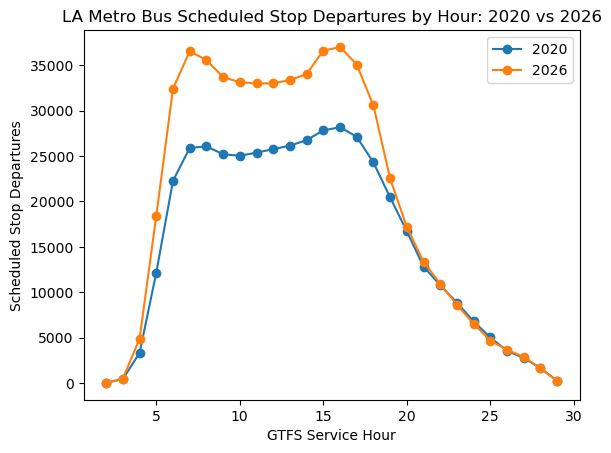

In [120]:
hourly_comparison=pd.DataFrame({'2020':hourly_2020,'2026':hourly_2026}).fillna(0)
hourly_comparison.plot.line(title='LA Metro Bus Scheduled Stop Departures by Hour: 2020 vs 2026',
                            xlabel='GTFS Service Hour', ylabel='Scheduled Stop Departures',
                            marker='o')
print("2020 total scheduled stop departures:", int(hourly_2020.sum()))
print("2026 total scheduled stop departures:", int(hourly_2026.sum()))


Figure 3. Comparison of scheduled LA Metro bus stop departures within the City of LA on October 19,2020, and October 19, 2026, grouped by GTFS service hour. Total scheduled stop departures increased from 441,595 in 2020 to 560,197 in 2026, representing a 26.9% increase. The largest differences occur during daytime hours, particularly between 6am & 5pm, while evening and late-night service levels remain relatively similar. Despite the decline in recorded bus stops, the increase in scheduled departures suggests that bus service activity became more concentrated across the remaining stops. Counts represent scheduled departures at stops rather than unique buses or routes.